# 00 — Audit détaillé des 35 variables

**Objectif :** vérifier un fichier annoncé comme nettoyé, sans considérer automatiquement une valeur rare comme fausse. À exécuter avant les analyses 01 à 04. Aucun recodage, aucune suppression et aucune écriture dans le classeur source.

Le chargement d’audit conserve les chaînes brutes et leurs espaces, sans passer par le nettoyage commun de `load_data`. Une copie numérique permet les calculs ; les conversions impossibles sont signalées. Les numéros de ligne correspondent au classeur original.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "quality.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "quality.py").exists():
    raise RuntimeError("Lancer depuis la racine ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display
from src.quality import read_raw, typed_copy, profile, review_variable, find_anomalies, iqr_alerts
raw = read_raw()
numeric_columns = ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
df = typed_copy(raw, numeric_columns)
print(f"{len(raw)} lignes, {raw.shape[1]} colonnes source")
print("L’index ligne_excel inclut l’en-tête en ligne 1.")

1518 lignes, 35 colonnes source
L’index ligne_excel inclut l’en-tête en ligne 1.


## 1. Inventaire et formats
Le nombre de valeurs distinctes correspond aux valeurs réellement présentes. Vérifier les cellules vides, les espaces et les valeurs non numériques avant les contrôles métier.

In [2]:
inventaire = profile(raw, df)
display(inventaire)
print("Doublons complets :", raw.duplicated().sum())
print("Identifiants dupliqués :", raw.EmployeeNumber.duplicated().sum())
print("Constantes :", raw.columns[raw.nunique(dropna=False).eq(1)].tolist())
assert set(raw.columns) == set(numeric_columns + ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']), "Adapter l’audit aux colonnes du fichier."

,variable,type_analyse,effectif,vides,espaces_exterieurs,valeurs_distinctes_brutes,non_numeriques,minimum,maximum
0,Age,int64,1518,0,0,44,0,18.0,61.0
1,Attrition,object,1518,0,0,2,0,NaN,NaN
2,BusinessTravel,object,1518,0,0,3,0,NaN,NaN
3,DailyRate,int64,1518,0,0,901,0,102.0,1499.0
4,Department,object,1518,0,0,3,0,NaN,NaN
5,DistanceFromHome,int64,1518,0,0,30,0,0.0,29.0
6,Education,int64,1518,0,0,7,0,0.0,6.0
7,EducationField,object,1518,0,0,6,0,NaN,NaN
8,EmployeeCount,int64,1518,0,0,1,0,1.0,1.0
9,EmployeeNumber,int64,1518,0,0,1518,0,1.0,1518.0


Doublons complets : 0
Identifiants dupliqués : 0
Constantes : ['EmployeeCount', 'Over18', 'StandardHours']


## 2. Bornes observées et contrôles de libellés
**Aucun dictionnaire métier n’est fourni.** On n’impose donc aucune plage numérique supposée. Le tableau ci-dessous décrit le minimum, le maximum et le nombre de valeurs distinctes de chaque variable numérique. Ce sont des observations, pas des bornes de validité : une erreur éventuelle peut elle-même déterminer le minimum ou le maximum.

Les listes de libellés restent des hypothèses explicites à confirmer. Les contrôles de types, de non-négativité et de cohérence entre anciennetés sont conservés séparément. Les indicateurs monétaires n’ont pas de plafond inventé.

In [3]:
expected = {
    "Attrition": ["Yes", "No"], "OverTime": ["Yes", "No"], "Over18": ["Y"],
    "Gender": ["Female", "Male"],
    "BusinessTravel": ["Non-Travel", "Travel_Rarely", "Travel_Frequently"],
    "Department": ["Sales", "Research & Development", "Human Resources"],
    "MaritalStatus": ["Single", "Married", "Divorced"]}
bornes_observees = pd.DataFrame({
    "variable": numeric_columns,
    "minimum_observe": [df[col].min() for col in numeric_columns],
    "maximum_observe": [df[col].max() for col in numeric_columns],
    "valeurs_distinctes": [df[col].nunique() for col in numeric_columns],
    "statut": "Description du fichier ; validité métier non vérifiée"})
display(bornes_observees)
anomalies = find_anomalies(raw, df, numeric_columns, expected)

,variable,minimum_observe,maximum_observe,valeurs_distinctes,statut
0,Age,18,61,44,Description du fichier ; validité métier non v...
1,DailyRate,102,1499,901,Description du fichier ; validité métier non v...
2,DistanceFromHome,0,29,30,Description du fichier ; validité métier non v...
3,Education,0,6,7,Description du fichier ; validité métier non v...
4,EmployeeCount,1,1,1,Description du fichier ; validité métier non v...
5,EmployeeNumber,1,1518,1518,Description du fichier ; validité métier non v...
6,EnvironmentSatisfaction,0,5,6,Description du fichier ; validité métier non v...
7,HourlyRate,30,101,72,Description du fichier ; validité métier non v...
8,JobInvolvement,0,5,6,Description du fichier ; validité métier non v...
9,JobLevel,0,5,6,Description du fichier ; validité métier non v...


## 3. Comment lire les fiches par variable
Chaque fiche affiche les effectifs des modalités ou les quantiles et extrêmes, un graphique (sauf pour l’identifiant), puis les lignes signalées par les règles. **Une fiche sans alerte n’est pas une certification de validité.**

Pour retrouver une observation dans Excel, utiliser `ligne_excel`, et non `EmployeeNumber` : ils ne sont pas nécessairement identiques. Les résultats restent dans le notebook ; seuls les résumés agrégés sont exportés.

### 3.01 — Age : Âge du salarié
Examiner les âges extrêmes et la compatibilité avec l’expérience. Les bornes observées décrivent le fichier ; aucune plage métier non documentée n’est imposée.

Age : 1518 lignes ; 44 valeurs distinctes brutes


,valeur
count,1518.000000
mean,37.027009
std,9.217789
min,18.000000
1%,19.000000
25%,30.000000
50%,36.000000
75%,43.000000
99%,59.000000
max,61.000000


,minimums,maximums
0,18,61
1,18,60
2,18,60
3,18,60
4,18,60


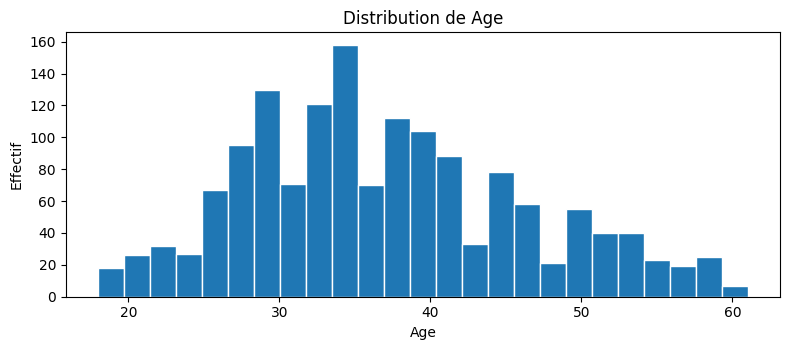

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [4]:
review_variable(raw, df, "Age")
cas = anomalies.loc[anomalies.variable.eq("Age")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.02 — Attrition : Départ observé
Vérifier Yes/No, les vides et la répartition. La période n’est pas documentée : pas de taux annuel.

Attrition : 1518 lignes ; 2 valeurs distinctes brutes


,valeur_brute,effectif,part
0,No,1270,0.836627
1,Yes,248,0.163373


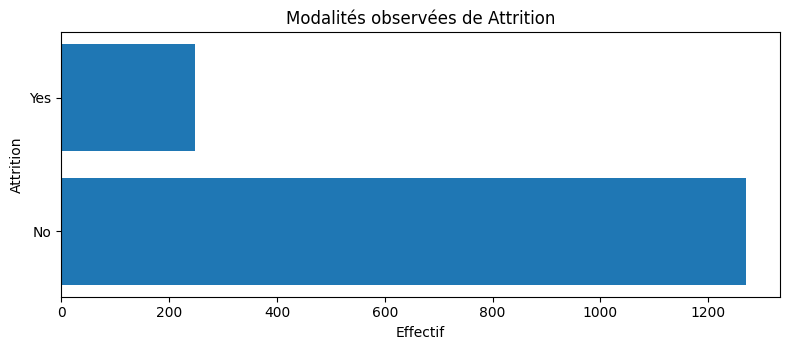

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [5]:
review_variable(raw, df, "Attrition")
cas = anomalies.loc[anomalies.variable.eq("Attrition")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.03 — BusinessTravel : Fréquence des déplacements
Afficher toutes les modalités et vérifier les libellés ; aucune mesure du nombre de jours.

BusinessTravel : 1518 lignes ; 3 valeurs distinctes brutes


,valeur_brute,effectif,part
0,Travel_Rarely,1074,0.707510
1,Travel_Frequently,287,0.189065
2,Non-Travel,157,0.103426


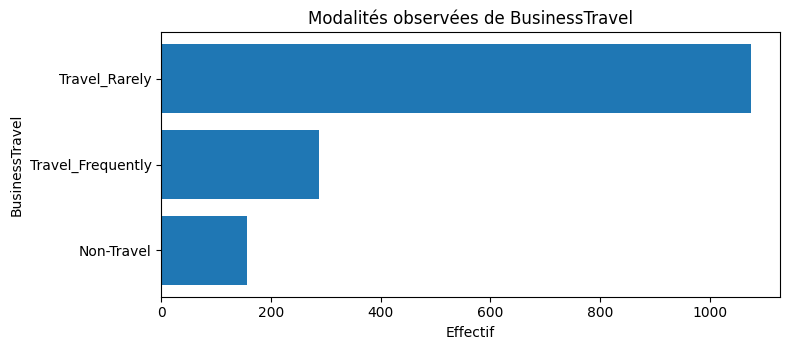

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [6]:
review_variable(raw, df, "BusinessTravel")
cas = anomalies.loc[anomalies.variable.eq("BusinessTravel")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.04 — DailyRate : Montant ou indicateur journalier
Le sens exact, l’unité et la devise restent à confirmer. Ne pas le confondre avec le revenu mensuel.

DailyRate : 1518 lignes ; 901 valeurs distinctes brutes


,valeur
count,1518.000000
mean,801.438735
std,404.866440
min,102.000000
1%,117.000000
25%,464.000000
50%,800.000000
75%,1161.000000
99%,1485.000000
max,1499.000000


,minimums,maximums
0,102,1499
1,103,1498
2,104,1496
3,105,1496
4,106,1495


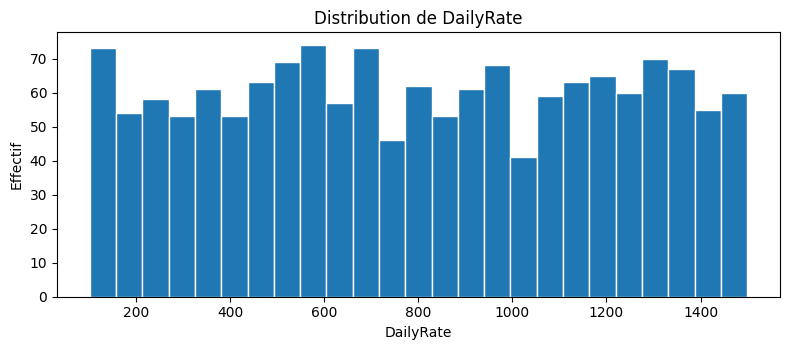

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [7]:
review_variable(raw, df, "DailyRate")
cas = anomalies.loc[anomalies.variable.eq("DailyRate")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.05 — Department : Département
Vérifier les libellés, variantes d’écriture et groupes rares.

Department : 1518 lignes ; 3 valeurs distinctes brutes


,valeur_brute,effectif,part
0,Research & Development,995,0.655468
1,Sales,458,0.301713
2,Human Resources,65,0.042819


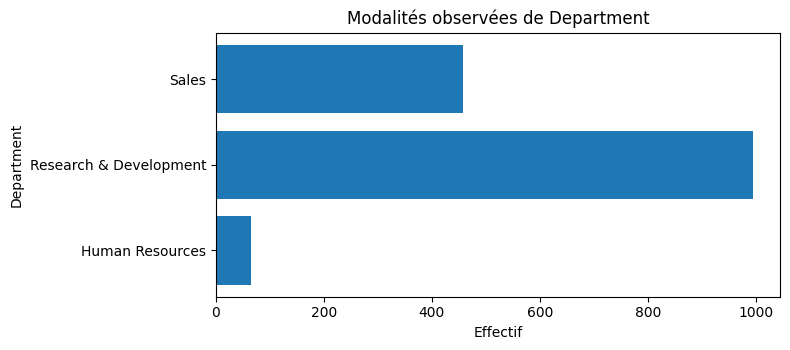

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [8]:
review_variable(raw, df, "Department")
cas = anomalies.loc[anomalies.variable.eq("Department")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.06 — DistanceFromHome : Distance domicile-travail
Zéro peut être valide ; vérifier les extrêmes et l’unité avant de juger une valeur.

DistanceFromHome : 1518 lignes ; 30 valeurs distinctes brutes


,valeur
count,1518.000000
mean,9.194335
std,8.122808
min,0.000000
1%,1.000000
25%,2.000000
50%,7.000000
75%,14.000000
99%,29.000000
max,29.000000


,valeur_brute,effectif,part
0,2,217,0.142951
1,1,211,0.138999
2,3,90,0.059289
3,10,90,0.059289
4,9,86,0.056653
5,7,86,0.056653
6,8,82,0.054018
7,5,67,0.044137
8,4,66,0.043478
9,6,60,0.039526


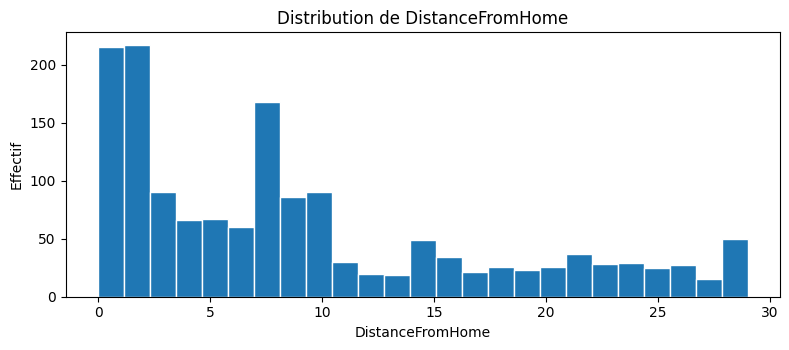

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [9]:
review_variable(raw, df, "DistanceFromHome")
cas = anomalies.loc[anomalies.variable.eq("DistanceFromHome")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.07 — Education : Niveau d’études codé
Afficher tous les codes présents et leurs effectifs. Leur signification et les codes autorisés demandent un dictionnaire.

Education : 1518 lignes ; 7 valeurs distinctes brutes


,valeur
count,1518.000000
mean,2.911726
std,1.039805
min,0.000000
1%,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
99%,5.000000
max,6.000000


,valeur_brute,effectif,part
0,3,584,0.384717
1,4,415,0.273386
2,2,288,0.189723
3,1,176,0.115942
4,5,50,0.032938
5,0,4,0.002635
6,6,1,0.000659


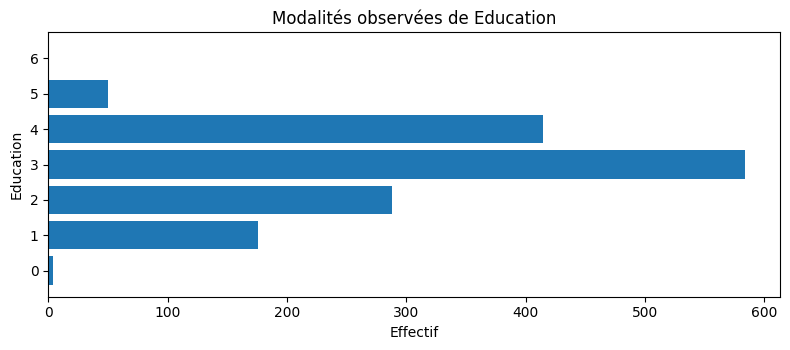

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [10]:
review_variable(raw, df, "Education")
cas = anomalies.loc[anomalies.variable.eq("Education")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.08 — EducationField : Domaine d’études
Contrôler les libellés et catégories rares. Aucune correspondance obligatoire avec le métier n’est imposée.

EducationField : 1518 lignes ; 6 valeurs distinctes brutes


,valeur_brute,effectif,part
0,Life Sciences,630,0.415020
1,Medical,474,0.312253
2,Marketing,163,0.107378
3,Technical Degree,138,0.090909
4,Other,86,0.056653
5,Human Resources,27,0.017787


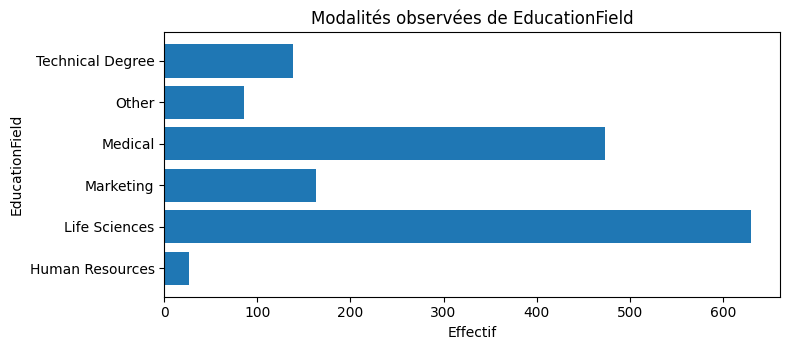

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [11]:
review_variable(raw, df, "EducationField")
cas = anomalies.loc[anomalies.variable.eq("EducationField")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.09 — EmployeeCount : Compteur de salariés
Vérifier sa constance et sa définition ; cette colonne ne représente pas à elle seule l’effectif du fichier.

EmployeeCount : 1518 lignes ; 1 valeurs distinctes brutes


,valeur
count,1518.0
mean,1.0
std,0.0
min,1.0
1%,1.0
25%,1.0
50%,1.0
75%,1.0
99%,1.0
max,1.0


,valeur_brute,effectif,part
0,1,1518,1.0


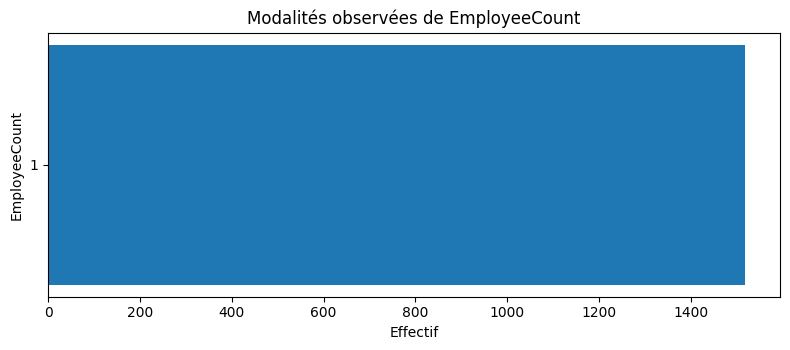

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [12]:
review_variable(raw, df, "EmployeeCount")
cas = anomalies.loc[anomalies.variable.eq("EmployeeCount")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.10 — EmployeeNumber : Identifiant salarié
Contrôler unicité, vides et type. Un saut dans la numérotation n’est pas une erreur ; exclure du modèle.

In [13]:
review_variable(raw, df, "EmployeeNumber")
cas = anomalies.loc[anomalies.variable.eq("EmployeeNumber")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

EmployeeNumber : 1518 lignes ; 1518 valeurs distinctes brutes


,valeur
count,1518.000000
mean,759.500000
std,438.353168
min,1.000000
1%,16.170000
25%,380.250000
50%,759.500000
75%,1138.750000
99%,1502.830000
max,1518.000000


,minimums,maximums
0,1,1518
1,2,1517
2,3,1516
3,4,1515
4,5,1514


Identifiant : une distribution numérique ne mesure pas un phénomène RH.
0 alertes (plusieurs règles peuvent concerner une même ligne)


### 3.11 — EnvironmentSatisfaction : Satisfaction de l’environnement
Afficher toutes les modalités présentes sans imposer une échelle 1-4 ; le sens des codes reste à confirmer.

EnvironmentSatisfaction : 1518 lignes ; 6 valeurs distinctes brutes


,valeur
count,1518.000000
mean,2.706851
std,1.122829
min,0.000000
1%,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
99%,4.000000
max,5.000000


,valeur_brute,effectif,part
0,4,462,0.304348
1,3,457,0.301054
2,1,295,0.194335
3,2,290,0.191041
4,0,11,0.007246
5,5,3,0.001976


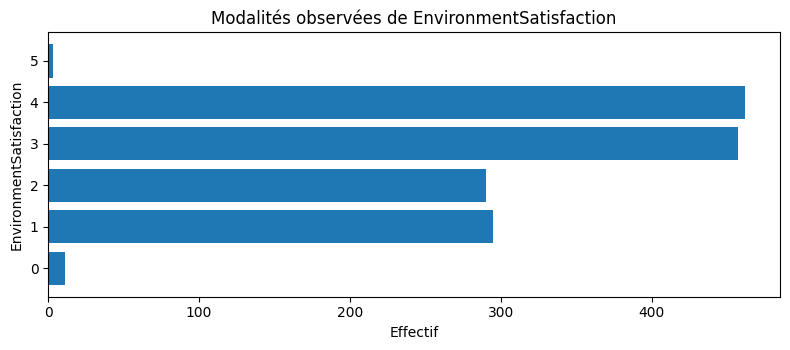

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [14]:
review_variable(raw, df, "EnvironmentSatisfaction")
cas = anomalies.loc[anomalies.variable.eq("EnvironmentSatisfaction")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.12 — Gender : Genre renseigné
Vérifier les libellés du fichier ; Female/Male décrit l’encodage actuel, sans prétendre couvrir toutes les identités possibles.

Gender : 1518 lignes ; 2 valeurs distinctes brutes


,valeur_brute,effectif,part
0,Male,913,0.601449
1,Female,605,0.398551


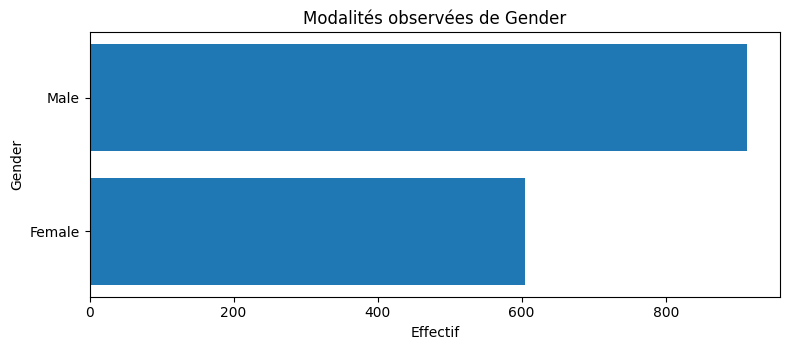

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [15]:
review_variable(raw, df, "Gender")
cas = anomalies.loc[anomalies.variable.eq("Gender")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.13 — HourlyRate : Montant ou indicateur horaire
Définition et devise non documentées ; ne pas imposer une équivalence avec MonthlyIncome sans heures réellement travaillées.

HourlyRate : 1518 lignes ; 72 valeurs distinctes brutes


,valeur
count,1518.000000
mean,66.074440
std,20.371316
min,30.000000
1%,30.000000
25%,48.000000
50%,66.000000
75%,84.000000
99%,100.000000
max,101.000000


,minimums,maximums
0,30,101
1,30,100
2,30,100
3,30,100
4,30,100


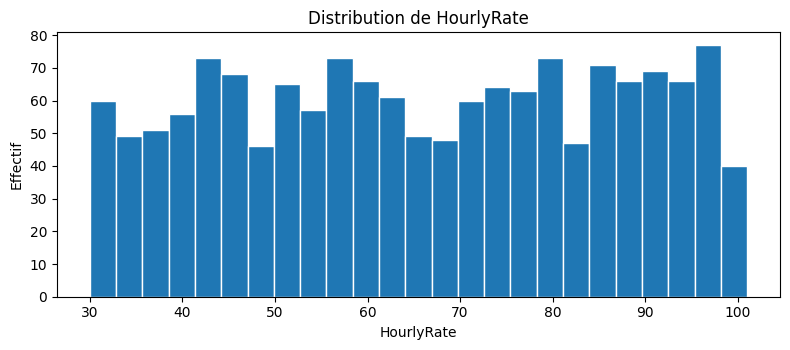

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [16]:
review_variable(raw, df, "HourlyRate")
cas = anomalies.loc[anomalies.variable.eq("HourlyRate")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.14 — JobInvolvement : Implication codée
Afficher tous les codes observés et leurs effectifs ; aucun code n’est rejeté sur la base d’une plage supposée.

JobInvolvement : 1518 lignes ; 6 valeurs distinctes brutes


,valeur
count,1518.000000
mean,2.715415
std,0.756017
min,0.000000
1%,1.000000
25%,2.000000
50%,3.000000
75%,3.000000
99%,4.000000
max,5.000000


,valeur_brute,effectif,part
0,3,878,0.578393
1,2,383,0.252306
2,4,157,0.103426
3,1,89,0.058630
4,0,10,0.006588
5,5,1,0.000659


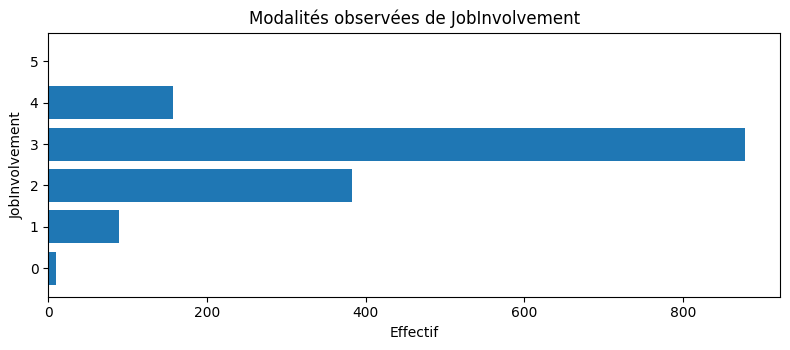

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [17]:
review_variable(raw, df, "JobInvolvement")
cas = anomalies.loc[anomalies.variable.eq("JobInvolvement")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.15 — JobLevel : Niveau hiérarchique codé
Décrire tous les niveaux présents, y compris zéro. Leur validité doit être confirmée avec les RH.

JobLevel : 1518 lignes ; 6 valeurs distinctes brutes


,valeur
count,1518.000000
mean,2.072464
std,1.129116
min,0.000000
1%,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
99%,5.000000
max,5.000000


,valeur_brute,effectif,part
0,1,550,0.362319
1,2,545,0.359025
2,3,225,0.148221
3,4,114,0.075099
4,5,75,0.049407
5,0,9,0.005929


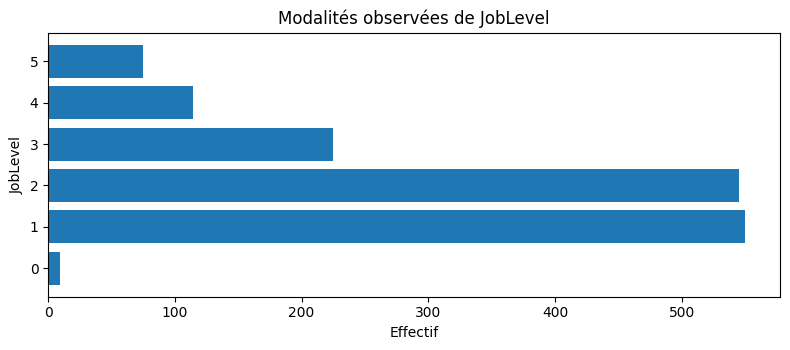

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [18]:
review_variable(raw, df, "JobLevel")
cas = anomalies.loc[anomalies.variable.eq("JobLevel")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.16 — JobRole : Métier
Vérifier les modalités et les effectifs ; un couple métier/niveau rare peut être réel.

JobRole : 1518 lignes ; 9 valeurs distinctes brutes


,valeur_brute,effectif,part
0,Sales Executive,333,0.219368
1,Research Scientist,300,0.197628
2,Laboratory Technician,267,0.175889
3,Manufacturing Director,152,0.100132
4,Healthcare Representative,137,0.090250
5,Manager,103,0.067852
6,Sales Representative,88,0.057971
7,Research Director,84,0.055336
8,Human Resources,54,0.035573


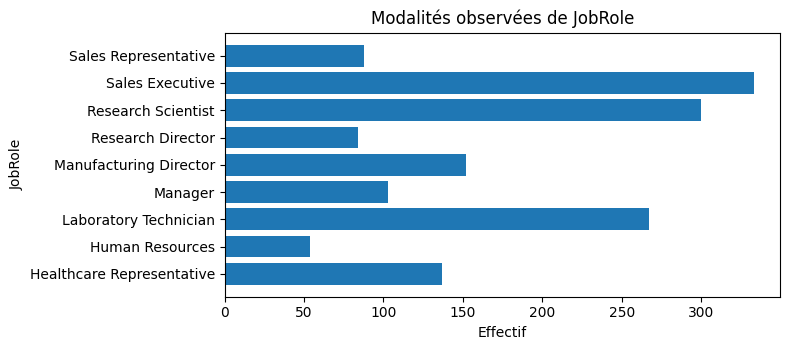

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [19]:
review_variable(raw, df, "JobRole")
cas = anomalies.loc[anomalies.variable.eq("JobRole")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.17 — JobSatisfaction : Satisfaction au travail
Afficher toutes les modalités observées sans plage supposée ni recodage.

JobSatisfaction : 1518 lignes ; 6 valeurs distinctes brutes


,valeur
count,1518.000000
mean,2.723979
std,1.117178
min,0.000000
1%,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
99%,4.000000
max,5.000000


,valeur_brute,effectif,part
0,4,474,0.312253
1,3,448,0.295125
2,1,294,0.193676
3,2,293,0.193017
4,0,6,0.003953
5,5,3,0.001976


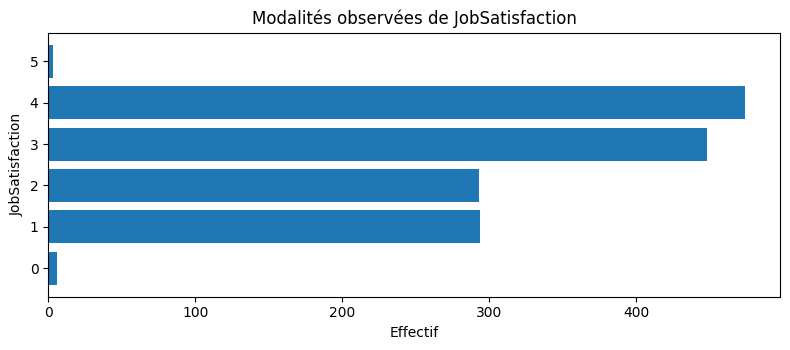

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [20]:
review_variable(raw, df, "JobSatisfaction")
cas = anomalies.loc[anomalies.variable.eq("JobSatisfaction")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.18 — MaritalStatus : Situation matrimoniale
Vérifier les libellés du fichier ; leur liste doit être validée et n’est pas une norme universelle.

MaritalStatus : 1518 lignes ; 3 valeurs distinctes brutes


,valeur_brute,effectif,part
0,Married,697,0.459157
1,Single,484,0.318841
2,Divorced,337,0.222003


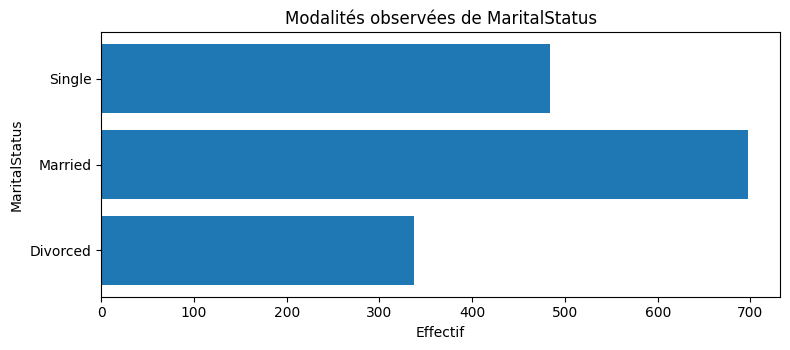

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [21]:
review_variable(raw, df, "MaritalStatus")
cas = anomalies.loc[anomalies.variable.eq("MaritalStatus")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.19 — MonthlyIncome : Revenu mensuel
Examiner quantiles et extrêmes ; un revenu élevé peut être légitime. Devise et temps de travail inconnus.

MonthlyIncome : 1518 lignes ; 1385 valeurs distinctes brutes


,valeur
count,1518.000000
mean,6507.700922
std,4697.570242
min,1009.000000
1%,1396.910000
25%,2926.750000
50%,4938.500000
75%,8379.000000
99%,19623.790000
max,19999.000000


,minimums,maximums
0,1009,19999
1,1051,19973
2,1052,19943
3,1081,19926
4,1091,19859


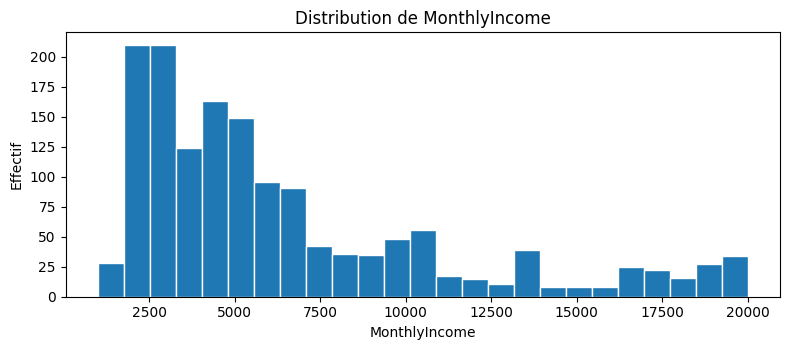

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [22]:
review_variable(raw, df, "MonthlyIncome")
cas = anomalies.loc[anomalies.variable.eq("MonthlyIncome")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.20 — MonthlyRate : Montant ou indicateur mensuel
Définition non confirmée ; ne pas assimiler à MonthlyIncome ni imposer de relation entre les deux.

MonthlyRate : 1518 lignes ; 1463 valeurs distinctes brutes


,valeur
count,1518.000000
mean,14308.193676
std,7153.989651
min,2094.000000
1%,2305.570000
25%,8009.750000
50%,14220.000000
75%,20489.750000
99%,26688.720000
max,26999.000000


,minimums,maximums
0,2094,26999
1,2097,26997
2,2104,26968
3,2110,26959
4,2112,26956


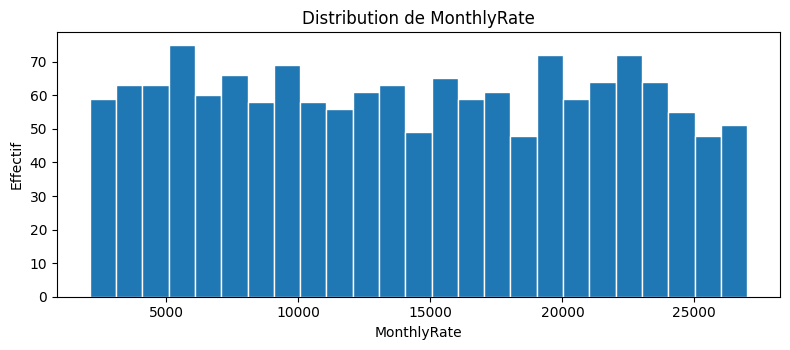

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [23]:
review_variable(raw, df, "MonthlyRate")
cas = anomalies.loc[anomalies.variable.eq("MonthlyRate")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.21 — NumCompaniesWorked : Nombre d’entreprises
Vérifier entier et non-négativité ; zéro ne doit pas être supprimé sans préciser si l’entreprise actuelle est comptée.

NumCompaniesWorked : 1518 lignes ; 10 valeurs distinctes brutes


,valeur
count,1518.000000
mean,2.698287
std,2.493210
min,0.000000
1%,0.000000
25%,1.000000
50%,2.000000
75%,4.000000
99%,9.000000
max,9.000000


,valeur_brute,effectif,part
0,1,529,0.348485
1,0,205,0.135046
2,3,166,0.109354
3,2,156,0.102767
4,4,142,0.093544
5,7,77,0.050725
6,6,76,0.050066
7,5,65,0.042819
8,9,53,0.034914
9,8,49,0.032279


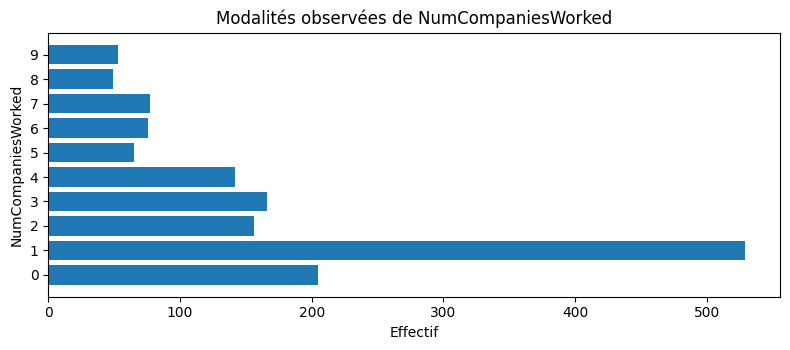

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [24]:
review_variable(raw, df, "NumCompaniesWorked")
cas = anomalies.loc[anomalies.variable.eq("NumCompaniesWorked")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.22 — Over18 : Indicateur de majorité
Comparer aux âges observés et vérifier la constance ; un code unique est sans intérêt prédictif.

Over18 : 1518 lignes ; 1 valeurs distinctes brutes


,valeur_brute,effectif,part
0,Y,1518,1.0


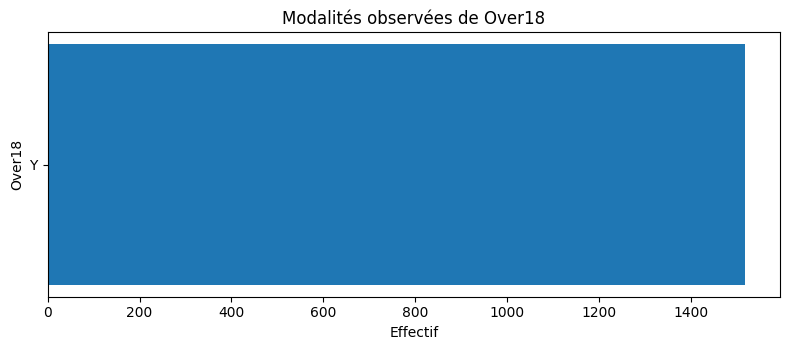

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [25]:
review_variable(raw, df, "Over18")
cas = anomalies.loc[anomalies.variable.eq("Over18")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.23 — OverTime : Heures supplémentaires déclarées
Vérifier Yes/No ; cette variable ne donne pas le volume d’heures supplémentaires.

OverTime : 1518 lignes ; 2 valeurs distinctes brutes


,valeur_brute,effectif,part
0,No,1086,0.715415
1,Yes,432,0.284585


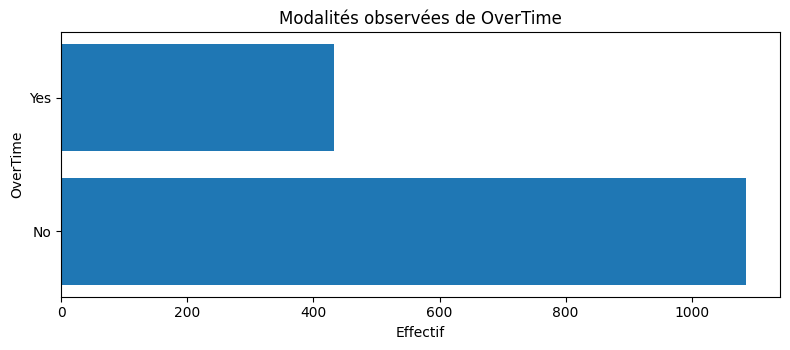

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [26]:
review_variable(raw, df, "OverTime")
cas = anomalies.loc[anomalies.variable.eq("OverTime")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.24 — PercentSalaryHike : Augmentation de salaire renseignée
Vérifier signe et distribution ; aucune borne supérieure arbitraire n’est imposée, période inconnue.

PercentSalaryHike : 1518 lignes ; 17 valeurs distinctes brutes


,valeur
count,1518.000000
mean,15.217391
std,3.647835
min,9.000000
1%,11.000000
25%,12.000000
50%,14.000000
75%,18.000000
99%,25.000000
max,25.000000


,valeur_brute,effectif,part
0,11,215,0.141634
1,13,215,0.141634
2,14,205,0.135046
3,12,199,0.131094
4,15,106,0.069829
5,18,95,0.062582
6,17,89,0.058630
7,16,81,0.053360
8,19,78,0.051383
9,20,58,0.038208


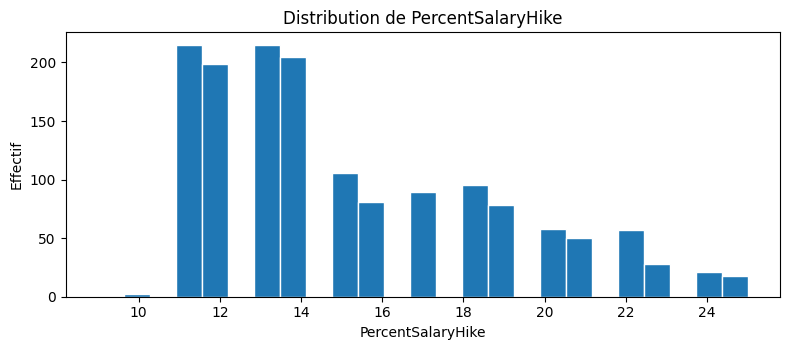

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [27]:
review_variable(raw, df, "PercentSalaryHike")
cas = anomalies.loc[anomalies.variable.eq("PercentSalaryHike")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.25 — PerformanceRating : Évaluation de performance codée
Afficher tous les codes présents, y compris les moins fréquents ; aucune plage officielle n’est disponible.

PerformanceRating : 1518 lignes ; 5 valeurs distinctes brutes


,valeur
count,1518.000000
mean,3.148221
std,0.408907
min,1.000000
1%,2.000000
25%,3.000000
50%,3.000000
75%,3.000000
99%,4.000000
max,5.000000


,valeur_brute,effectif,part
0,3,1252,0.824769
1,4,245,0.161397
2,2,14,0.009223
3,1,5,0.003294
4,5,2,0.001318


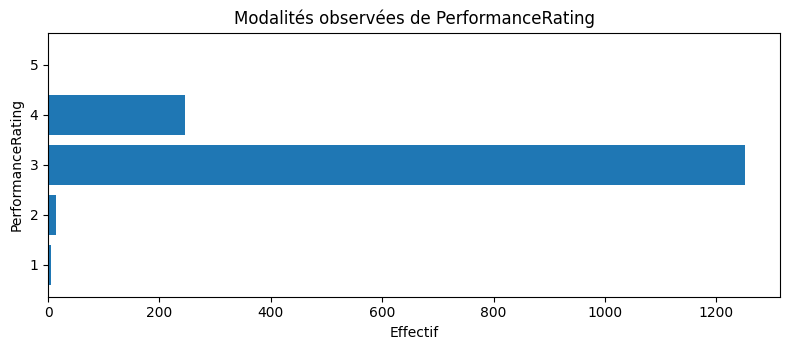

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [28]:
review_variable(raw, df, "PerformanceRating")
cas = anomalies.loc[anomalies.variable.eq("PerformanceRating")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.26 — RelationshipSatisfaction : Satisfaction relationnelle
Afficher toutes les modalités observées sans plage supposée ; vérifier leur signification avec un dictionnaire.

RelationshipSatisfaction : 1518 lignes ; 5 valeurs distinctes brutes


,valeur
count,1518.000000
mean,2.699605
std,1.094428
min,0.000000
1%,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
99%,4.000000
max,4.000000


,valeur_brute,effectif,part
0,3,471,0.310277
1,4,444,0.292490
2,2,314,0.206851
3,1,281,0.185112
4,0,8,0.005270


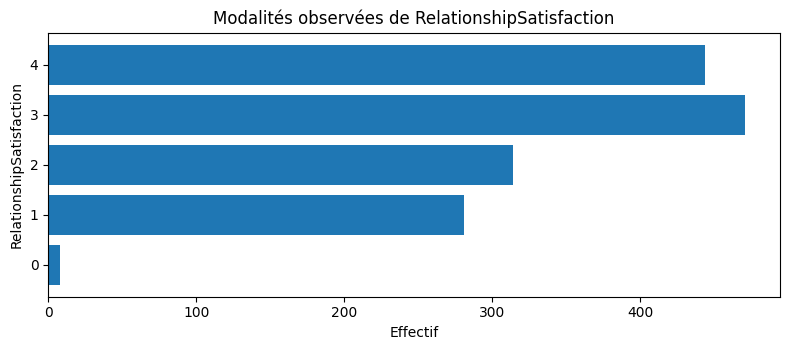

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [29]:
review_variable(raw, df, "RelationshipSatisfaction")
cas = anomalies.loc[anomalies.variable.eq("RelationshipSatisfaction")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.27 — StandardHours : Horaire standard
Vérifier sa constance et son unité ; aucune conclusion sur les heures réelles ou l’absentéisme.

StandardHours : 1518 lignes ; 1 valeurs distinctes brutes


,valeur
count,1518.0
mean,80.0
std,0.0
min,80.0
1%,80.0
25%,80.0
50%,80.0
75%,80.0
99%,80.0
max,80.0


,valeur_brute,effectif,part
0,80,1518,1.0


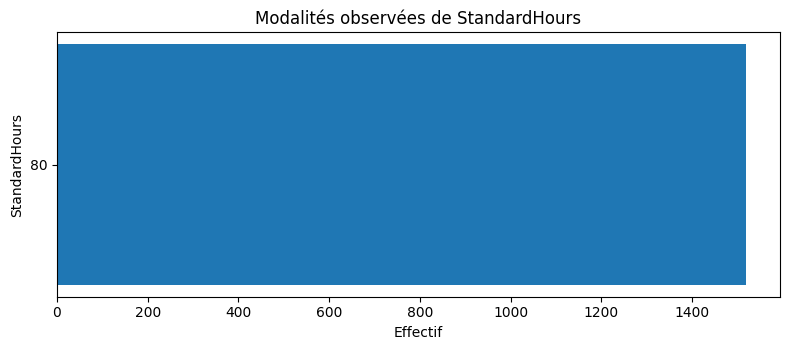

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [30]:
review_variable(raw, df, "StandardHours")
cas = anomalies.loc[anomalies.variable.eq("StandardHours")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.28 — StockOptionLevel : Niveau d’options sur actions
Décrire tous les codes présents ; zéro peut représenter une absence d’options, à confirmer.

StockOptionLevel : 1518 lignes ; 5 valeurs distinctes brutes


,valeur
count,1518.000000
mean,0.810277
std,0.870433
min,0.000000
1%,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
99%,3.000000
max,4.000000


,valeur_brute,effectif,part
0,0,648,0.426877
1,1,606,0.399209
2,2,170,0.111989
3,3,92,0.060606
4,4,2,0.001318


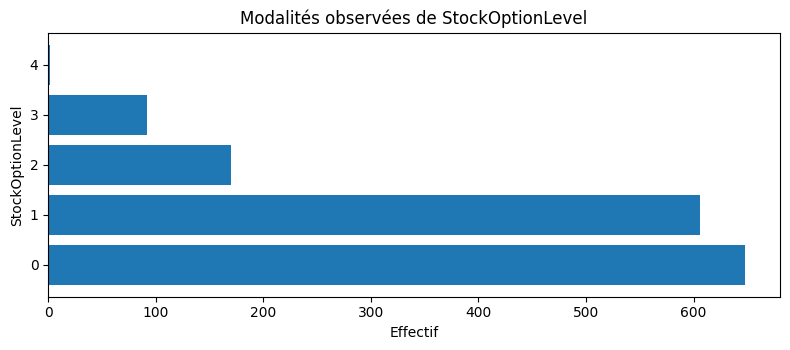

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [31]:
review_variable(raw, df, "StockOptionLevel")
cas = anomalies.loc[anomalies.variable.eq("StockOptionLevel")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.29 — TotalWorkingYears : Expérience professionnelle totale
Vérifier entier, non-négativité, comparaison à l’âge et à l’ancienneté dans l’entreprise.

TotalWorkingYears : 1518 lignes ; 40 valeurs distinctes brutes


,valeur
count,1518.000000
mean,11.289196
std,7.767894
min,0.000000
1%,1.000000
25%,6.000000
50%,10.000000
75%,15.000000
99%,34.830000
max,40.000000


,valeur_brute,effectif,part
0,10,205,0.135046
1,6,126,0.083004
2,8,105,0.069170
3,9,99,0.065217
4,5,91,0.059947
5,1,83,0.054677
6,7,81,0.053360
7,4,66,0.043478
8,12,49,0.032279
9,3,45,0.029644


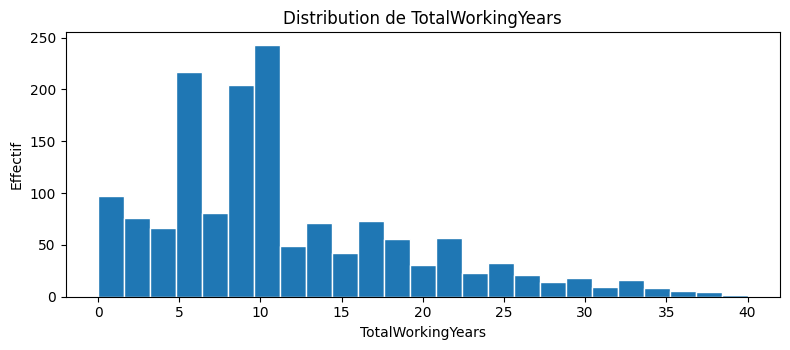

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [32]:
review_variable(raw, df, "TotalWorkingYears")
cas = anomalies.loc[anomalies.variable.eq("TotalWorkingYears")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.30 — TrainingTimesLastYear : Nombre de formations sur la dernière année
Vérifier les entiers et les extrêmes ; aucune borne haute n’est certaine sans définition des sessions.

TrainingTimesLastYear : 1518 lignes ; 8 valeurs distinctes brutes


,valeur
count,1518.000000
mean,2.806983
std,1.315304
min,0.000000
1%,0.000000
25%,2.000000
50%,3.000000
75%,3.000000
99%,6.000000
max,7.000000


,valeur_brute,effectif,part
0,2,553,0.364295
1,3,501,0.330040
2,4,133,0.087615
3,5,124,0.081686
4,1,77,0.050725
5,6,67,0.044137
6,0,60,0.039526
7,7,3,0.001976


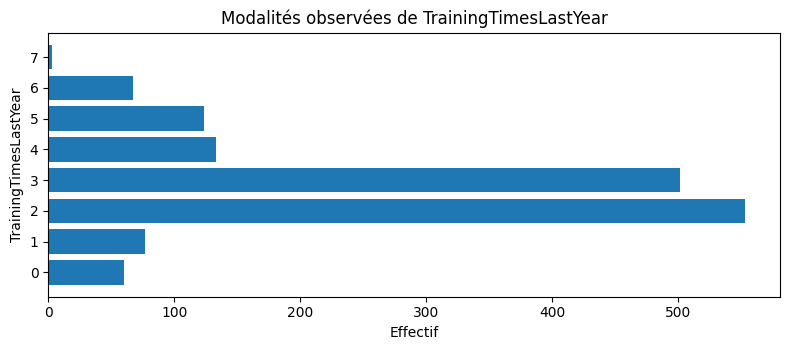

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [33]:
review_variable(raw, df, "TrainingTimesLastYear")
cas = anomalies.loc[anomalies.variable.eq("TrainingTimesLastYear")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.31 — WorkLifeBalance : Équilibre vie professionnelle/personnelle
Afficher tous les codes réellement présents, sans imposer une échelle 1-4. Les bornes observées ne prouvent pas la validité des codes.

WorkLifeBalance : 1518 lignes ; 7 valeurs distinctes brutes


,valeur
count,1518.000000
mean,2.752964
std,0.751339
min,0.000000
1%,1.000000
25%,2.000000
50%,3.000000
75%,3.000000
99%,4.000000
max,6.000000


,valeur_brute,effectif,part
0,3,899,0.592227
1,2,357,0.235178
2,4,162,0.106719
3,1,89,0.058630
4,5,5,0.003294
5,0,5,0.003294
6,6,1,0.000659


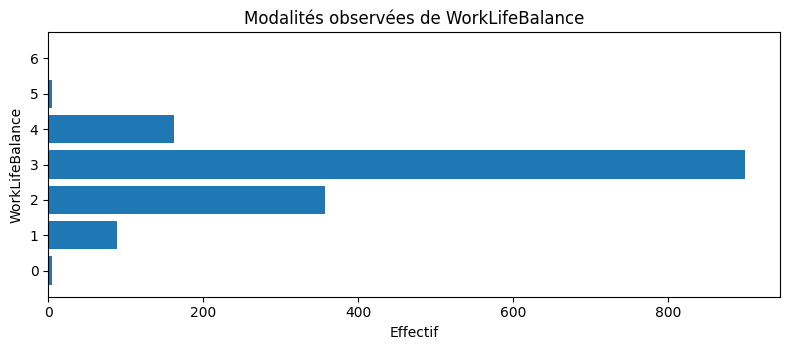

0 alertes (plusieurs règles peuvent concerner une même ligne)


In [34]:
review_variable(raw, df, "WorkLifeBalance")
cas = anomalies.loc[anomalies.variable.eq("WorkLifeBalance")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.32 — YearsAtCompany : Ancienneté dans l’entreprise
Elle ne devrait pas dépasser l’expérience totale si ces notions utilisent les mêmes conventions.

YearsAtCompany : 1518 lignes ; 37 valeurs distinctes brutes


,valeur
count,1518.000000
mean,6.995389
std,6.110980
min,0.000000
1%,0.000000
25%,3.000000
50%,5.000000
75%,9.000000
99%,30.830000
max,40.000000


,valeur_brute,effectif,part
0,5,199,0.131094
1,1,173,0.113966
2,3,133,0.087615
3,2,129,0.084980
4,10,123,0.081028
5,4,113,0.074440
6,7,92,0.060606
7,9,88,0.057971
8,6,81,0.053360
9,8,81,0.053360


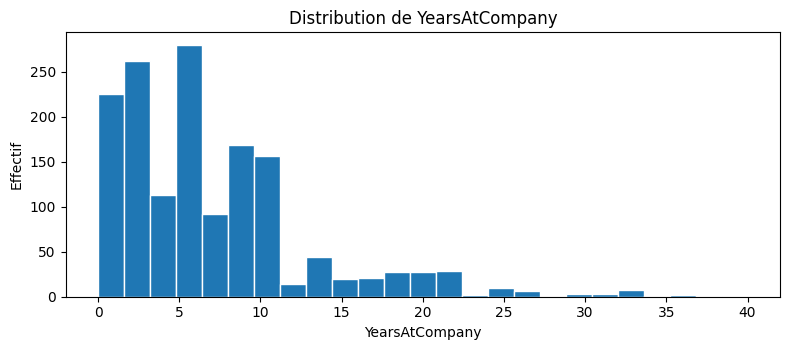

6 alertes (plusieurs règles peuvent concerner une même ligne)


,ligne_excel,EmployeeNumber,variable,categorie,regle,valeur
0,1484,1483,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,5 > 3
1,1486,1485,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,18 > 17
2,1495,1494,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,3 > 0
3,1502,1501,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,6 > 4
4,1515,1514,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,9 > 8
5,1516,1515,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,5 > 3


In [35]:
review_variable(raw, df, "YearsAtCompany")
cas = anomalies.loc[anomalies.variable.eq("YearsAtCompany")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.33 — YearsInCurrentRole : Ancienneté dans le rôle actuel
Comparer à l’ancienneté entreprise ; vérifier le traitement des mobilités ou reprises d’ancienneté.

YearsInCurrentRole : 1518 lignes ; 19 valeurs distinctes brutes


,valeur
count,1518.000000
mean,4.218709
std,3.629821
min,0.000000
1%,0.000000
25%,2.000000
50%,3.000000
75%,7.000000
99%,15.000000
max,18.000000


,valeur_brute,effectif,part
0,2,376,0.247694
1,0,256,0.168643
2,7,225,0.148221
3,3,140,0.092227
4,4,109,0.071805
5,8,93,0.061265
6,9,69,0.045455
7,1,62,0.040843
8,5,39,0.025692
9,6,39,0.025692


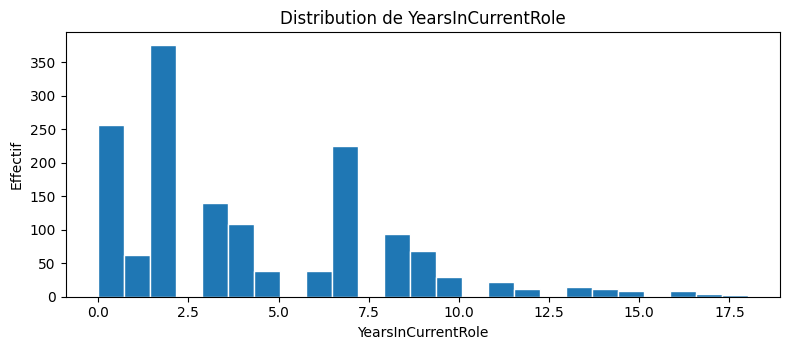

7 alertes (plusieurs règles peuvent concerner une même ligne)


,ligne_excel,EmployeeNumber,variable,categorie,regle,valeur
6,1472,1471,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,12 > 10
7,1474,1473,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,3 > 2
8,1475,1474,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,8 > 6
9,1479,1478,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,3 > 0
10,1489,1488,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,1 > 0
11,1497,1496,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,2 > 1
12,1501,1500,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,3 > 1


In [36]:
review_variable(raw, df, "YearsInCurrentRole")
cas = anomalies.loc[anomalies.variable.eq("YearsInCurrentRole")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.34 — YearsSinceLastPromotion : Délai depuis la dernière promotion
Comparer à l’ancienneté ; zéro peut avoir plusieurs sens. Ce délai n’est pas un taux de promotion.

YearsSinceLastPromotion : 1518 lignes ; 16 valeurs distinctes brutes


,valeur
count,1518.000000
mean,2.184453
std,3.228739
min,0.000000
1%,0.000000
25%,0.000000
50%,1.000000
75%,3.000000
99%,14.000000
max,15.000000


,valeur_brute,effectif,part
0,0,602,0.396574
1,1,365,0.240448
2,2,166,0.109354
3,7,77,0.050725
4,4,63,0.041502
5,3,56,0.036891
6,5,47,0.030962
7,6,32,0.021080
8,11,24,0.015810
9,8,18,0.011858


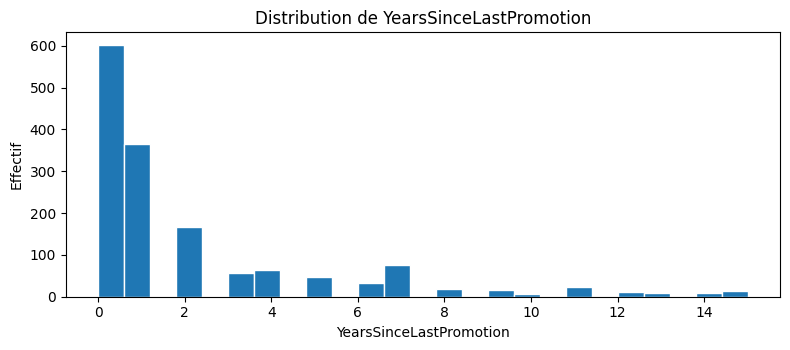

4 alertes (plusieurs règles peuvent concerner une même ligne)


,ligne_excel,EmployeeNumber,variable,categorie,regle,valeur
13,1479,1478,YearsSinceLastPromotion,cohérence entre variables,YearsSinceLastPromotion > YearsAtCompany,1 > 0
14,1481,1480,YearsSinceLastPromotion,cohérence entre variables,YearsSinceLastPromotion > YearsAtCompany,2 > 0
15,1496,1495,YearsSinceLastPromotion,cohérence entre variables,YearsSinceLastPromotion > YearsAtCompany,5 > 4
16,1501,1500,YearsSinceLastPromotion,cohérence entre variables,YearsSinceLastPromotion > YearsAtCompany,4 > 1


In [37]:
review_variable(raw, df, "YearsSinceLastPromotion")
cas = anomalies.loc[anomalies.variable.eq("YearsSinceLastPromotion")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

### 3.35 — YearsWithCurrManager : Ancienneté avec le manager actuel
Comparer à l’ancienneté entreprise et vérifier les conventions RH.

YearsWithCurrManager : 1518 lignes ; 18 valeurs distinctes brutes


,valeur
count,1518.000000
mean,4.121212
std,3.574584
min,0.000000
1%,0.000000
25%,2.000000
50%,3.000000
75%,7.000000
99%,14.000000
max,17.000000


,valeur_brute,effectif,part
0,2,349,0.229908
1,0,273,0.179842
2,7,216,0.142292
3,3,149,0.098155
4,8,113,0.074440
5,4,102,0.067194
6,1,81,0.053360
7,9,68,0.044796
8,5,35,0.023057
9,6,29,0.019104


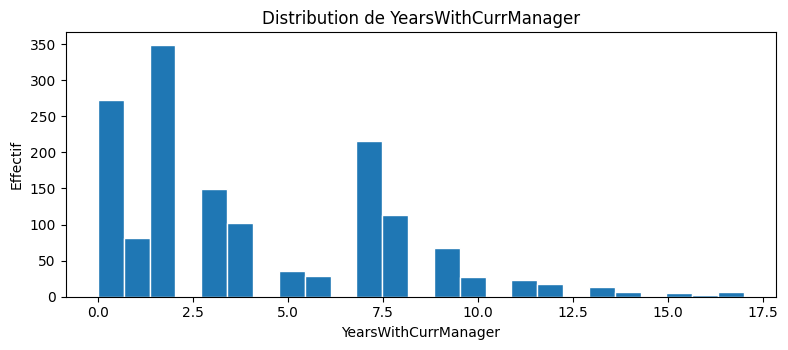

6 alertes (plusieurs règles peuvent concerner une même ligne)


,ligne_excel,EmployeeNumber,variable,categorie,regle,valeur
17,1475,1474,YearsWithCurrManager,cohérence entre variables,YearsWithCurrManager > YearsAtCompany,9 > 6
18,1476,1475,YearsWithCurrManager,cohérence entre variables,YearsWithCurrManager > YearsAtCompany,4 > 3
19,1488,1487,YearsWithCurrManager,cohérence entre variables,YearsWithCurrManager > YearsAtCompany,2 > 0
20,1505,1504,YearsWithCurrManager,cohérence entre variables,YearsWithCurrManager > YearsAtCompany,1 > 0
21,1510,1509,YearsWithCurrManager,cohérence entre variables,YearsWithCurrManager > YearsAtCompany,4 > 3
22,1517,1516,YearsWithCurrManager,cohérence entre variables,YearsWithCurrManager > YearsAtCompany,1 > 0


In [38]:
review_variable(raw, df, "YearsWithCurrManager")
cas = anomalies.loc[anomalies.variable.eq("YearsWithCurrManager")]
print(f"{len(cas)} alertes (plusieurs règles peuvent concerner une même ligne)")
if not cas.empty:
    display(cas)

## 4. Toutes les incohérences entre variables
Afficher les deux valeurs comparées, le numéro de ligne Excel et l’identifiant pour faciliter une vérification dans la source. Ne pas additionner les alertes pour obtenir un nombre de salariés : une même personne peut être signalée plusieurs fois.

In [39]:
coherence = anomalies.loc[anomalies.categorie.eq("cohérence entre variables")]
display(coherence)
print("Lignes distinctes concernées :", coherence.ligne_excel.nunique())
contexte = ["EmployeeNumber", "Age", "TotalWorkingYears", "YearsAtCompany",
            "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager"]
display(df.loc[sorted(coherence.ligne_excel.unique()), contexte])

,ligne_excel,EmployeeNumber,variable,categorie,regle,valeur
0,1484,1483,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,5 > 3
1,1486,1485,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,18 > 17
2,1495,1494,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,3 > 0
3,1502,1501,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,6 > 4
4,1515,1514,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,9 > 8
5,1516,1515,YearsAtCompany,cohérence entre variables,YearsAtCompany > TotalWorkingYears,5 > 3
6,1472,1471,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,12 > 10
7,1474,1473,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,3 > 2
8,1475,1474,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,8 > 6
9,1479,1478,YearsInCurrentRole,cohérence entre variables,YearsInCurrentRole > YearsAtCompany,3 > 0


Lignes distinctes concernées : 20


,EmployeeNumber,Age,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
ligne_excel,,,,,,,
1472,1471,56,13,10,12,4,9
1474,1473,23,4,2,3,0,1
1475,1474,40,12,6,8,1,9
1476,1475,25,5,3,1,0,4
1479,1478,58,1,0,3,1,0
1481,1480,19,0,0,0,2,0
1484,1483,29,3,5,4,2,3
1486,1485,52,17,18,7,2,14
1488,1487,20,0,0,0,0,2


## 5. Valeurs statistiquement atypiques : des pistes, pas des erreurs
La règle de l’écart interquartile (IQR) repère les valeurs en dehors de [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]. Elle peut signaler des rémunérations élevées ou des carrières longues parfaitement valides. On l’applique aux quantités numériques, pas aux identifiants ou scores codés. Ne pas supprimer automatiquement ces valeurs.

In [40]:
quantities = ["Age", "DailyRate", "HourlyRate", "MonthlyIncome", "MonthlyRate",
              "DistanceFromHome", "NumCompaniesWorked", "PercentSalaryHike",
              "TotalWorkingYears", "TrainingTimesLastYear", "YearsAtCompany",
              "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager"]
atypiques = iqr_alerts(df, quantities)
display(atypiques)
# Modifier cette variable pour examiner les cas d’une distribution.
variable_a_examiner = "MonthlyIncome"
limites = atypiques.set_index("variable").loc[variable_a_examiner]
mask = ~df[variable_a_examiner].between(limites.borne_basse_iqr, limites.borne_haute_iqr) & df[variable_a_examiner].notna()
display(df.loc[mask, ["EmployeeNumber", variable_a_examiner]].sort_values(variable_a_examiner))

,variable,borne_basse_iqr,borne_haute_iqr,effectif_atypique
0,Age,10.500,62.500,0
1,DailyRate,-581.500,2206.500,0
2,HourlyRate,-6.000,138.000,0
3,MonthlyIncome,-5251.625,16557.375,117
4,MonthlyRate,-10710.250,39209.750,0
5,DistanceFromHome,-16.000,32.000,0
6,NumCompaniesWorked,-3.500,8.500,53
7,PercentSalaryHike,3.000,27.000,0
8,TotalWorkingYears,-7.500,28.500,64
9,TrainingTimesLastYear,0.500,4.500,254


,EmployeeNumber,MonthlyIncome
ligne_excel,,
468,467,16595
1045,1044,16598
1082,1081,16606
491,490,16627
1505,1504,16629
...,...,...
570,569,19859
167,166,19926
853,852,19943


## 6. Synthèse des alertes et exports agrégés
Les alertes sont séparées par règle et catégorie ; aucune alerte ne repose sur une plage numérique supposée. Les résumés ne constituent pas une liste d’erreurs avérées. Les lignes individuelles ne sont pas exportées en CSV ; elles restent consultables ci-dessus.

In [41]:
synthese = (anomalies.groupby(["categorie", "variable", "regle"], dropna=False)
            .agg(nombre_alertes=("ligne_excel", "size"), lignes_distinctes=("ligne_excel", "nunique"))
            .reset_index())
display(synthese)
print("Total d’alertes :", len(anomalies))
print("Lignes distinctes avec au moins une alerte :", anomalies.ligne_excel.nunique())
print("Les alertes sont des cas à examiner, pas nécessairement des erreurs.")
from src.data import export_table
export_table(inventaire, "00_audit_inventaire")
export_table(synthese, "00_audit_synthese")
export_table(atypiques, "00_audit_atypiques_iqr");

,categorie,variable,regle,nombre_alertes,lignes_distinctes
0,cohérence entre variables,YearsAtCompany,YearsAtCompany > TotalWorkingYears,6,6
1,cohérence entre variables,YearsInCurrentRole,YearsInCurrentRole > YearsAtCompany,7,7
2,cohérence entre variables,YearsSinceLastPromotion,YearsSinceLastPromotion > YearsAtCompany,4,4
3,cohérence entre variables,YearsWithCurrManager,YearsWithCurrManager > YearsAtCompany,6,6


Total d’alertes : 23
Lignes distinctes avec au moins une alerte : 20
Les alertes sont des cas à examiner, pas nécessairement des erreurs.


## 7. Décider quoi faire après l’audit

1. **Confirmer les définitions** : unités, périodes, dictionnaire des scores, sens du zéro et conventions d’ancienneté.
2. **Vérifier les lignes signalées** auprès du détenteur des données, en distinguant erreur de saisie, convention métier et valeur réelle atypique.
3. **Tracer chaque correction validée** dans un fichier distinct (ligne, variable, ancienne valeur, nouvelle valeur, justification), sans écraser la source.
4. **Réexécuter les analyses** sur une copie corrigée après validation et comparer les conclusions. Ce notebook n’applique aucune correction.

L’absence d’alerte ne prouve pas que le dataset est exact. Les dates, pays et données de présence ne sont pas disponibles : la chronologie des départs, la représentativité pour l’Afrique et l’absentéisme ne peuvent pas être contrôlés avec ce seul fichier.